# 003. Intersystem crossing between $^3E$ and $^1A_1$ of the NV$^-$ center in MgO: harmonic and anharmonic vibrational overlap functions

In this notebook we compute the vibrational overlap function (VOF) $F(\Delta)$ of the intersystem crossing (ISC) from the
triplet $^3E$ to the singlet $^1A_1$ of the negatively charged nitrogen-vacancy center NV$^-$ in MgO, and the ISC rate
it gives. The potential energy surfaces (PES) come from WEST TDDFT calculations with the dielectric-dependent hybrid
functional (DDH) along a one-dimensional configurational coordinate (1D CCD).

Two VOFs are compared:

1. **Harmonic, PyPL's own solver** (`config_coord_1d_solver`, Franck-Condon integrals from the Ruhoff recurrences): each
   PES is a parabola fitted to the images near its minimum, as in Tutorial 002.
2. **Anharmonic, smooth not-a-knot spline**: each PES is a cubic spline through *every* image, with smooth ($C^2$) tails
   beyond the last images. The vibrational states are solved numerically on that potential with finite differences, and
   each line of the VOF sits at the actual level energies of the two wells.

The notebook is organized into five parts:

1. Construction of the 1D CCD from the WEST data
2. Harmonic and smooth-spline fits of the two PES
3. The two VOFs and their comparison
4. Huang-Rhys factors beyond the harmonic approximation
5. The ISC rate $\Gamma_{A_1}(\Delta)$ and lifetime from each VOF

> **Note.** Besides `config_coord_1d_solver`, this tutorial uses `config_coord_1d_potential` (fits of a sampled PES),
> `config_coord_1d_vof_solver` (a subclass of `config_coord_1d_solver` that adds the finite-difference route and line
> positions from the actual vibrational levels), `pypl.isc` (the golden-rule ISC rate) and `parse_west_summary` (WEST
> TDDFT excitation energies). The WEST data are in `003_nv_mgo_isc/` (see `003_nv_mgo_isc/README.md` and `NOTES.md` for how they were
> collected).

## 1. Construction of the one-dimensional configurational coordinate diagram

In [1]:
import os
import re

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const

from pypl.config_coord_1d_solver import config_coord_1d_solver
from pypl.config_coord_1d_potential import config_coord_1d_potential
from pypl.config_coord_1d_vof_solver import config_coord_1d_vof_solver
from pypl.isc import compute_isc_lifetime, compute_isc_rate
from pypl.utils import parse_atoms_qexml, parse_total_energy_qexml, parse_west_summary

plt.rcParams.update({"font.size": 12})

red = "#DB4437"   # 3E, as in 003_nv_mgo_isc/reference/ccd_nv_mgo.py
blue = "#4285F4"  # 1A1

DATA_DIR = "003_nv_mgo_isc"

The WEST bundle in `003_nv_mgo_isc/` holds, for every image `Image_<q>` along the linear path between the $^3E$ and the
$^1A_1$ equilibrium geometries:

- `qe/Image_<q>/data-file-schema.xml`: the ground-state ($^3A_2$) Quantum ESPRESSO run (DDH, PBE0 form with
  $\alpha = 0.34$);
- `sc/Image_<q>/summary.json`: spin-conserving TDDFT; root 1 is $^3E$;
- `sf/Image_<q>/summary.json`: spin-flip TDDFT; roots 1-4 are the $m_s = 0$ triplet, $^1B_2$, $^1B_1$ and $^1A_1$.

The path coordinate $q$ is read from the directory name: $q = 0$ is the $^3E$ minimum and $q = 1$ the $^1A_1$ minimum.
First, the mass-weighted displacement $\Delta Q$ between them.

In [2]:
xml = lambda image: os.path.join(DATA_DIR, "qe", image, "data-file-schema.xml")

# Unit of coordinates and cell parameters is Angstrom.
symbols, coord_3e, cell = parse_atoms_qexml(xml("Image_+0.00"))
symbols_2, coord_1a1, cell_2 = parse_atoms_qexml(xml("Image_+1.00"))
assert symbols == symbols_2, "Mismatch in atomic symbols between the 3E and 1A1 structures."
assert np.max(np.abs(cell - cell_2)) < 1e-12, "Mismatch in cell parameters."

mass_list = {"N": 14.0067, "O": 15.999, "Mg": 24.305}
masses = np.array([mass_list[s] for s in symbols])
delta_q = np.linalg.norm((coord_1a1 - coord_3e) * masses[:, None] ** 0.5)
print("Atoms: %d (%s)" % (len(symbols), ", ".join("%s%d" % (s, symbols.count(s)) for s in sorted(set(symbols)))))
print("Delta Q = %.6f amu^0.5 Angstrom" % delta_q)

Atoms: 216 (Mg107, N1, O108)
Delta Q = 3.097879 amu^0.5 Angstrom


The energy of an excited state at each image is the ground-state ($^3A_2$) DFT total energy, computed with the DDH
functional, plus the TDDFT excitation energy of its root, $E = E^\mathrm{DDH}_{^3A_2} + \omega_\mathrm{root}$, with
$Q = q\,\Delta Q$. So the $^3E$ points are spin-conserving TDDFT energies and the $^1A_1$ points spin-flip TDDFT
energies. As in `ccd_nv_mgo.py`, the energy zero is the
$^3A_2$ minimum. Every image is used: 33 for $^3E$ and 31 for $^1A_1$, from $q = -1$ to $q = +2$.

In [3]:
def image_q(name):
    match = re.fullmatch(r"Image_([+-]?\d+\.\d+)", name)
    return float(match.group(1)) if match else None


def load_state(run, root, exclude=()):
    # (q, E) of every image with a TDDFT summary and a QE XML, sorted by q.
    points = []
    for name in os.listdir(os.path.join(DATA_DIR, run)):
        q = image_q(name)
        summary = os.path.join(DATA_DIR, run, name, "summary.json")
        if q is None or name in exclude or not (os.path.exists(summary) and os.path.exists(xml(name))):
            continue
        omega = parse_west_summary(summary)[root]  # excitation energies in eV
        points.append((q, parse_total_energy_qexml(xml(name)) + omega))
    return np.array(sorted(points)).T


# Energy zero: the 3A2 minimum (Image_-1.00 excluded, as in ccd_nv_mgo.py).
e_zero = min(parse_total_energy_qexml(xml(n)) for n in os.listdir(os.path.join(DATA_DIR, "qe"))
             if image_q(n) is not None and n != "Image_-1.00")

q_3e, e_3e = load_state("sc", root=0)                          # 3E: spin-conserving root 1
q_1a1, e_1a1 = load_state("sf", root=3)                         # 1A1: spin-flip root 4
e_3e, e_1a1 = e_3e - e_zero, e_1a1 - e_zero
Q_3e, Q_1a1 = q_3e * delta_q, q_1a1 * delta_q

print("3E : %d images, q = %+.2f..%+.2f, minimum %.4f eV at q = %+.2f" % (len(q_3e), q_3e.min(), q_3e.max(), e_3e.min(), q_3e[np.argmin(e_3e)]))
print("1A1: %d images, q = %+.2f..%+.2f, minimum %.4f eV at q = %+.2f" % (len(q_1a1), q_1a1.min(), q_1a1.max(), e_1a1.min(), q_1a1[np.argmin(e_1a1)]))
print("Adiabatic gap E(3E, q = 0) - E(1A1, q = 1) = %.2f meV" % (1e3 * (e_3e.min() - e_1a1.min())))

3E : 33 images, q = -1.00..+2.00, minimum 3.1376 eV at q = +0.00
1A1: 31 images, q = -1.00..+2.00, minimum 2.5832 eV at q = +1.00
Adiabatic gap E(3E, q = 0) - E(1A1, q = 1) = 554.41 meV


## 2. Harmonic and smooth-spline fits of the two PES

**Harmonic fit.** The parabola $a(Q - Q_0)^2 + c$, with its minimum fixed at $Q_0 = 0$ ($^3E$) or $\Delta Q$ ($^1A_1$),
is fitted only to images near the minimum: $q = -0.10 \dots +0.45$ for $^3E$ and $q = +0.60 \dots +1.15$ for $^1A_1$. Its
curvature gives the effective phonon energy $\hbar\omega = \hbar\sqrt{2a/M}$ and the Huang-Rhys factor
$S = \omega\,\Delta Q^2 / 2\hbar$.

**Smooth not-a-knot spline.** A cubic spline through *all* images of each PES. The not-a-knot condition imposes nothing
at the end images, so the shape there comes from the data alone. Beyond the first and last image the spline is continued
by its own second-order Taylor expansion, $V(Q_e) + V'(Q_e)(Q - Q_e) + \tfrac12 V''(Q_e)(Q - Q_e)^2$, so the potential
is smooth ($C^2$) everywhere, as an electronic-structure PES is, and the tails add no assumption from elsewhere. The
tails are bound as long as $V'' > 0$ at both end images. See `validation/METHODS.md`, section 5.1.

In [4]:
def window(q, lo, hi):
    return np.where((q >= lo - 1e-9) & (q <= hi + 1e-9))[0]


def huang_rhys(phonon_mev):
    return config_coord_1d_vof_solver.huang_rhys(phonon_mev, delta_q)


# Harmonic parabolas (minimum fixed at each equilibrium geometry)
harm_3e = config_coord_1d_potential(Q_3e, e_3e, q0=0.0)
harm_3e.fit_parabola(window(q_3e, -0.10, 0.45))
harm_1a1 = config_coord_1d_potential(Q_1a1, e_1a1, q0=delta_q)
harm_1a1.fit_parabola(window(q_1a1, 0.60, 1.15))

phonon_3e, phonon_1a1 = harm_3e.phonon_energy(), harm_1a1.phonon_energy()
for name, pot, phonon in (("3E ", harm_3e, phonon_3e), ("1A1", harm_1a1, phonon_1a1)):
    print("%s harmonic: hbar w = %.4f meV, S = %.2f | %s" % (name, phonon, huang_rhys(phonon), pot.describe()))

# Smooth not-a-knot cubic splines through every image
spline_3e = config_coord_1d_potential(Q_3e, e_3e, q0=0.0)
spline_3e.fit_spline(order=3, bc="not-a-knot", tails="smooth")
spline_1a1 = config_coord_1d_potential(Q_1a1, e_1a1, q0=delta_q)
spline_1a1.fit_spline(order=3, bc="not-a-knot", tails="smooth")
for name, pot in (("3E ", spline_3e), ("1A1", spline_1a1)):
    assert pot.bounded, pot.describe()
    print("%s spline: hbar w at the minimum = %.2f meV | %s" % (name, pot.phonon_energy(), pot.describe()))

3E  harmonic: hbar w = 60.8332 meV, S = 69.83 | parabola a (Q - 0.000000)^2 + c, a = 0.442649 eV/(amu A^2), c = 3.160211 eV; fitted to samples 4-15 of 33 (Q = -0.310..1.394); rms residual 1.89e-02 eV
1A1 harmonic: hbar w = 31.5511 meV, S = 36.22 | parabola a (Q - 3.097879)^2 + c, a = 0.119071 eV/(amu A^2), c = 2.595544 eV; fitted to samples 18-29 of 31 (Q = 1.859..3.563); rms residual 1.05e-02 eV
3E  spline: hbar w at the minimum = 87.55 meV | cubic spline (degree 3, not-a-knot ends, 31 knots), smooth C2 Taylor tails from the spline's own ends (V' = -4.502 / +1.654 eV/(amu^0.5 A), V'' = +2.024 / +0.805 eV/(amu A^2) at Q = -3.098 / 6.196); fitted to samples 1-33 of 33 (Q = -3.098..6.196); rms residual 3.54e-16 eV
1A1 spline: hbar w at the minimum = 40.83 meV | cubic spline (degree 3, not-a-knot ends, 29 knots), smooth C2 Taylor tails from the spline's own ends (V' = -3.397 / +2.244 eV/(amu^0.5 A), V'' = +0.179 / +0.699 eV/(amu A^2) at Q = -3.098 / 6.196); fitted to samples 1-31 of 31 (Q

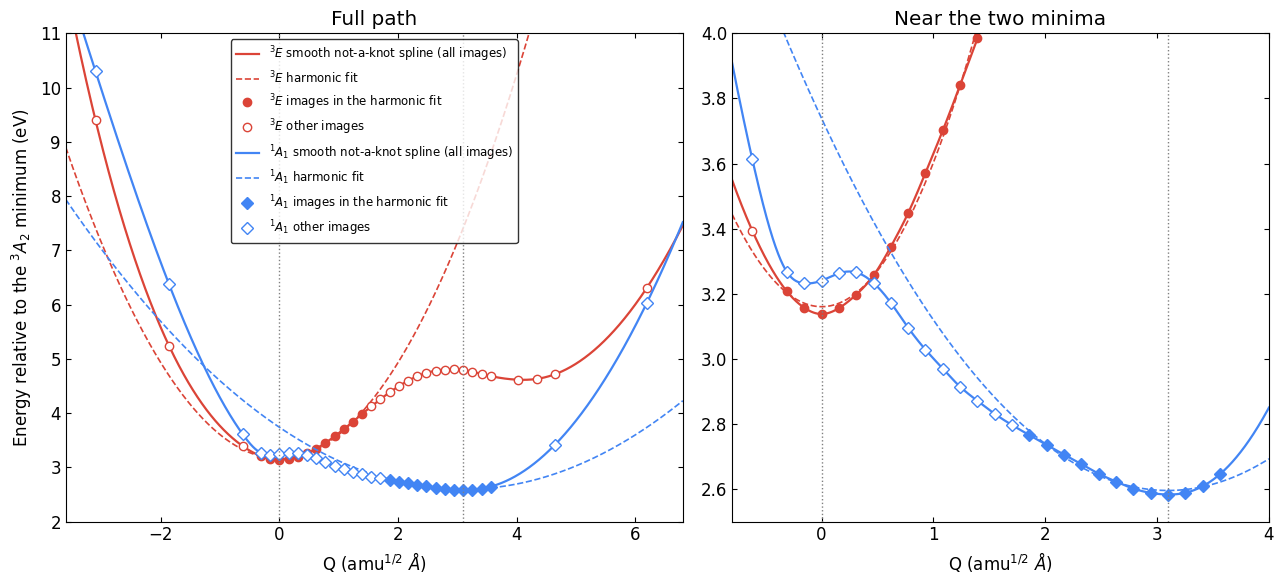

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.15, 1]})
q_plot = np.linspace(-3.6, 6.8, 3000)

for ax in axes:
    for pot_h, pot_s, Q, E, q_img, idx, color, marker, label in (
        (harm_3e, spline_3e, Q_3e, e_3e, q_3e, harm_3e.index, red, "o", r"$^3E$"),
        (harm_1a1, spline_1a1, Q_1a1, e_1a1, q_1a1, harm_1a1.index, blue, "D", r"$^1A_1$"),
    ):
        ax.plot(q_plot, pot_s(q_plot), color=color, lw=1.6, label="%s smooth not-a-knot spline (all images)" % label)
        ax.plot(q_plot, pot_h(q_plot), color=color, lw=1.2, ls="--", label="%s harmonic fit" % label)
        others = np.setdiff1d(np.arange(len(Q)), idx)
        ax.plot(Q[idx], E[idx], marker, color=color, ms=6, ls="", label="%s images in the harmonic fit" % label)
        ax.plot(Q[others], E[others], marker, mfc="white", mec=color, ms=6, ls="", label="%s other images" % label)
    for x in (0.0, delta_q):
        ax.axvline(x, color="gray", ls=":", lw=1)
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
    ax.tick_params(direction="in")
    ax.xaxis.set_ticks_position("both")
    ax.yaxis.set_ticks_position("both")

axes[0].set_xlim(q_plot[0], q_plot[-1])
axes[0].set_ylim(2.0, 11.0)
axes[0].set_ylabel(r"Energy relative to the $^3A_2$ minimum (eV)")
axes[0].set_title("Full path")
axes[1].set_xlim(-0.8, 4.0)
axes[1].set_ylim(2.5, 4.0)
axes[1].set_title("Near the two minima")
axes[0].legend(fontsize=8.5, loc="upper center", edgecolor="black")
plt.tight_layout()
plt.show()

The parabolas describe each PES only near its own minimum. Over the $\Delta Q \approx 3.1$ amu$^{1/2}$ Å that separates
the two minima, the $^3E$ surface softens and turns over, and the $^1A_1$ surface rises far less steeply towards the
$^3E$ geometry than its parabola. The spline follows every image. Note the shoulder of the $^1A_1$ root near $q \approx 0$,
about 0.1 eV above $^3E$: it sits exactly where the $^3E$ vibrational ground state lives, so it shapes the ISC overlap.

## 3. The two vibrational overlap functions

The ISC VOF at 5 K is

$$F(\Delta) = \sum_{i, j} p_i\,|\langle\chi^{^3E}_i|\chi^{^1A_1}_j\rangle|^2\,G(\Delta; E_{ij}, \sigma),$$

the Franck-Condon weight of every $^3E$ level $i$ (thermal population $p_i$) into every $^1A_1$ level $j$, broadened by a
Gaussian $G$ and placed at the energy $E_{ij}$ released into vibrations, measured from the 0-0 line.

In [6]:
# Delta axis (meV, from the 0-0 line)
delta_min_meV, delta_max_meV, n_delta_points = 0, 2000, 2001
Delta_axis = np.linspace(delta_min_meV, delta_max_meV, n_delta_points)

# Vibrational levels kept (initial = 3E, final = 1A1)
initial_order, final_order = 100, 100

# Broadening: Gaussian width [sigma_min, sigma_max] in meV (PyPL widens it linearly with energy), Lorentzian ZPL
sigma = [6, 8]
gamma_broadening = 0.3
temp = 5  # K

# Finite-difference grid of the spline route
fd_npts = 40001

**Harmonic VOF (PyPL).** `config_coord_1d_solver` with the two harmonic phonon energies and $\Delta Q$; the Franck-Condon
integrals come from the Ruhoff recurrences and the lines sit at $j\hbar\omega_{^1A_1} - i\hbar\omega_{^3E}$.

The Huang-Rhys factors here ($S \approx 70$ and $36$) are much larger than for NV$^-$ in diamond ($S \approx 3.5$), and the
recurrence loses accuracy for higher *initial* levels (it is reliable only up to $i \approx 10$ at these $S$). At 5 K
only $i = 0$ is populated ($p_1 \approx 10^{-61}$), whose row is exact, so the VOF is unaffected. Do not use these
$F_{ij}$ at high temperature without checking them (e.g. against `compute_franck_condon_integrals_hermite`).

In [7]:
ccd_harm = config_coord_1d_solver(omega_i=phonon_3e, omega_f=phonon_1a1, delta_q=delta_q)
ccd_harm.compute_franck_condon_integrals(ni=initial_order, nf=final_order)
ccd_harm.bulid_fc_lsp(eneaxis=Delta_axis, temp=temp, sigma=sigma, zpl_lorentzian=True, gamma=gamma_broadening)
F_harm = np.copy(ccd_harm.fc_lineshape)

print("closure of the populated level, sum_j |F_0j|^2 = %.10f" % np.sum(ccd_harm.fc_ints[0] ** 2))

Integral check: 0.9999999999203011
closure of the populated level, sum_j |F_0j|^2 = 1.0000000000


**Smooth-spline VOF.** The vibrational states of each spline well are solved with a 5-point finite-difference
Hamiltonian $-\tfrac{\hbar^2}{2}\,d^2/dQ^2 + V(Q)$ on a common grid (`compute_franck_condon_integrals_fd`), and the
overlaps $F_{ij}$ are taken between them. The lineshape is then built with `build_fc_lsp_from_levels`: the same sum,
Gaussian and Lorentzian as `bulid_fc_lsp`, but with each line at the difference of the actual level energies
$E_{ij} = (E^{^1A_1}_j - E^{^1A_1}_0) - (E^{^3E}_i - E^{^3E}_0)$. `bulid_fc_lsp` would place the anharmonic overlaps
at the harmonic positions $j\hbar\omega - i\hbar\omega'$, which belong to a different potential. With harmonic ladders
the two functions are identical.

In [8]:
ccd_spline = config_coord_1d_vof_solver(omega_i=phonon_3e, omega_f=phonon_1a1, delta_q=delta_q)
ccd_spline.compute_franck_condon_integrals_fd(
    initial_order, final_order, spline_3e, spline_1a1, q_i=0.0, q_f=delta_q, npts=fd_npts
)
ccd_spline.build_fc_lsp_from_levels(eneaxis=Delta_axis, temp=temp, sigma=sigma, zpl_lorentzian=True, gamma=gamma_broadening)
F_spline = np.copy(ccd_spline.fc_lineshape)

info = ccd_spline.fd_info
print("grid: %d points, Q = %.2f..%.2f, h = %.2e amu^0.5 A" % (info["npts"], *info["q_range"], info["h"]))
print("checks: |psi| at the walls / peak = %.1e, orthonormality = %.1e" % (info["wall"], info["orthonormality"]))
print("closure of the populated level, sum_j |F_0j|^2 = %.10f" % np.sum(ccd_spline.fc_ints[0] ** 2))

levels_3e = (ccd_spline.fd_energies_i - ccd_spline.fd_energies_i[0]) * 1e3
levels_1a1 = (ccd_spline.fd_energies_f - ccd_spline.fd_energies_f[0]) * 1e3
print("\nlevel     3E: spline / harmonic (meV)     1A1: spline / harmonic (meV)")
for v in (1, 2, 5, 10, 20, 30):
    print("v = %2d   %8.1f / %8.1f            %8.1f / %8.1f" % (v, levels_3e[v], v * phonon_3e, levels_1a1[v], v * phonon_1a1))

zero_zero_harm = 1e3 * (harm_3e.params["c"] - harm_1a1.params["c"]) + 0.5 * (phonon_3e - phonon_1a1)
zero_zero_spline = 1e3 * (ccd_spline.fd_energies_i[0] - ccd_spline.fd_energies_f[0])
print("\n0-0 line (including zero-point energies): harmonic %.1f meV, spline %.1f meV" % (zero_zero_harm, zero_zero_spline))

Integral check: 0.9999999957724226
grid: 40001 points, Q = -5.70..10.23, h = 3.98e-04 amu^0.5 A
checks: |psi| at the walls / peak = 5.6e-16, orthonormality = 3.4e-15
closure of the populated level, sum_j |F_0j|^2 = 1.0000000000

level     3E: spline / harmonic (meV)     1A1: spline / harmonic (meV)
v =  1       72.7 /     60.8                42.5 /     31.6
v =  2      141.8 /    121.7                83.8 /     63.1
v =  5      347.4 /    304.2               196.6 /    157.8
v = 10      675.0 /    608.3               373.9 /    315.5
v = 20     1275.7 /   1216.7               698.9 /    631.0
v = 30     1602.3 /   1825.0              1027.6 /    946.5

0-0 line (including zero-point energies): harmonic 579.3 meV, spline 571.4 meV


The spline $^1A_1$ well is stiffer than its parabola near the minimum and its levels spread out faster, while far from
the minimum it is much softer: the energy the $^1A_1$ vibrations must absorb to overlap the $^3E$ ground state is much
smaller than the parabolas predict. Below, both VOFs on the same axis.

In [9]:
def centroid(F):
    return np.sum(Delta_axis * F) / np.sum(F)


def width(F):
    c = centroid(F)
    return np.sqrt(np.sum((Delta_axis - c) ** 2 * F) / np.sum(F))


delta_highlight_meV = 554.41449  # adiabatic energy gap

rows = []
for name, F in (("harmonic (PyPL, Ruhoff)", F_harm), ("smooth not-a-knot spline", F_spline)):
    rows.append((name, Delta_axis[np.argmax(F)], centroid(F), width(F), np.interp(delta_highlight_meV, Delta_axis, F),
                 np.trapezoid(F, Delta_axis)))

print("=" * 96)
print("                       VOF COMPARISON, 3E -> 1A1, T = %g K" % temp)
print("=" * 96)
print("%-26s %14s %14s %12s %18s %10s" % ("VOF", "peak (meV)", "centroid (meV)", "rms width", "F(Delta_ad) (1/meV)", "integral"))
for name, peak, cen, wid, f_ad, integ in rows:
    print("%-26s %14.1f %14.1f %12.1f %18.4e %10.6f" % (name, peak, cen, wid, f_ad, integ))
print("-" * 96)
print("F_spline / F_harmonic at Delta_ad = %.2f meV: %.3e" % (delta_highlight_meV, rows[1][4] / rows[0][4]))
print("peak (Franck-Condon shift) moves by %+.1f meV, centroid by %+.1f meV" % (rows[1][1] - rows[0][1], rows[1][2] - rows[0][2]))
print("max |F_spline - F_harmonic| = %.3e 1/meV (%.1f times the harmonic peak)" % (np.max(np.abs(F_spline - F_harm)), np.max(np.abs(F_spline - F_harm)) / F_harm.max()))
print("=" * 96)

                       VOF COMPARISON, 3E -> 1A1, T = 5 K
VOF                            peak (meV) centroid (meV)    rms width F(Delta_ad) (1/meV)   integral
harmonic (PyPL, Ruhoff)            1145.0         1146.2        139.1         2.7045e-07   1.000000
smooth not-a-knot spline            660.0          662.2         26.4         4.0442e-05   1.000000
------------------------------------------------------------------------------------------------
F_spline / F_harmonic at Delta_ad = 554.41 meV: 1.495e+02
peak (Franck-Condon shift) moves by -485.0 meV, centroid by -484.0 meV
max |F_spline - F_harmonic| = 2.385e-02 1/meV (8.4 times the harmonic peak)


**Where the VOF comes from.** The figure below draws the first three vibrational states of each PES, $v = 0, 1, 2$ of
$^3E$ and $v' = 0, 1, 2$ of $^1A_1$, on their potentials at their level energies (left: harmonic wells, right: spline
wells), together with the $^1A_1$ state that overlaps the $^3E$ ground state most (thin line). At 5 K only $v = 0$ is
populated, so each line of the VOF is one weight $|F_{0v'}|^2 = |\langle\chi_0(^3E)|\chi_{v'}(^1A_1)\rangle|^2$ placed at
$\Delta = E_{v'} - E_{0'}$; the bottom panels show these weights for all 100 $^1A_1$ levels.

The low $^1A_1$ states are centred $\Delta Q \approx 3.1$ amu$^{1/2}$ Å away from the $^3E$ ground state and barely reach
it: $|F_{00}|^2 \sim 10^{-21}$, and the next two are only a few orders of magnitude larger. The overlap comes from
$^1A_1$ states high enough in energy to extend back to the $^3E$ geometry. In the harmonic wells these are spread over
many levels around $v' \approx S_{^1A_1} \approx 36$, about 1.15 eV above $E_{0'}$. In the spline wells the $^1A_1$
surface rises much less steeply towards $Q = 0$, so states around $v' = 18$, only about 0.66 eV up, already have a large
amplitude where $\chi_0(^3E)$ lives, and a single level carries most of the weight.

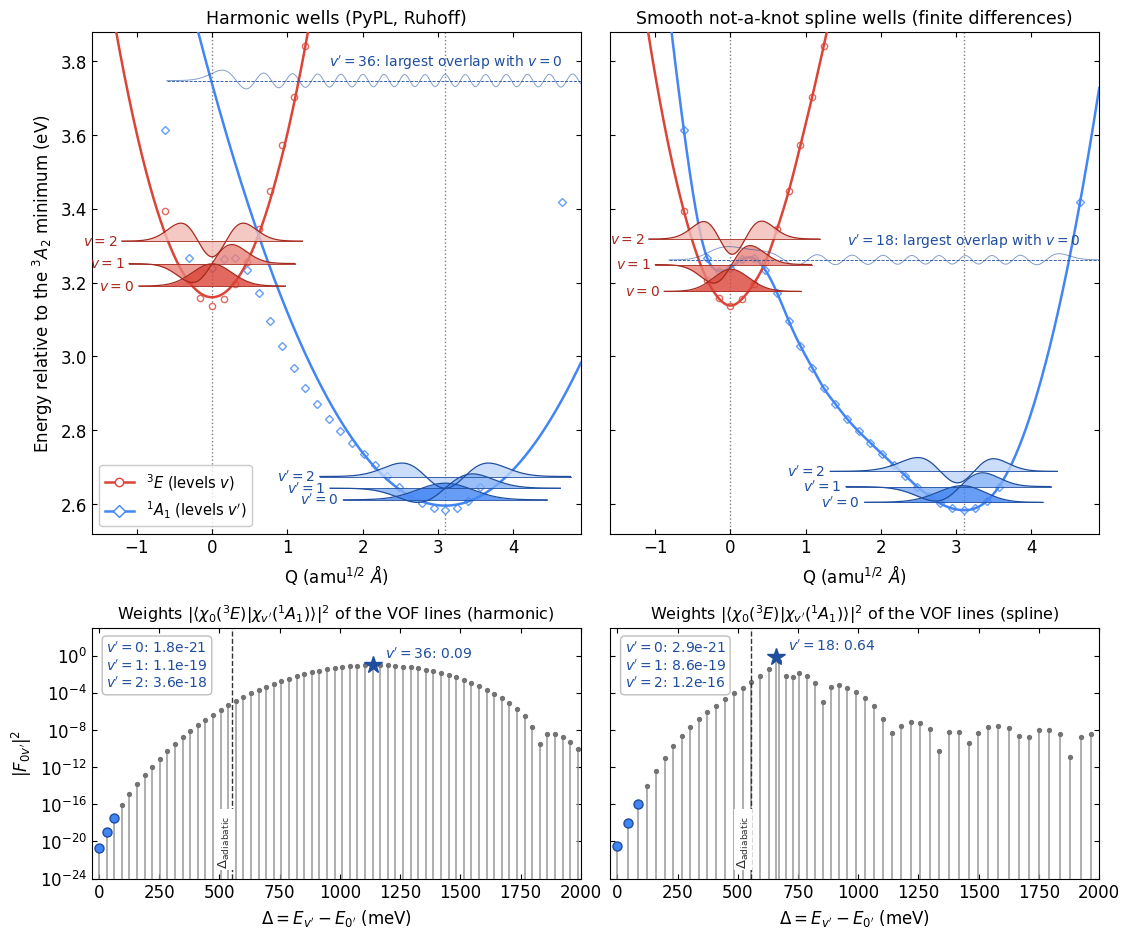

In [10]:
n_show = 3  # vibrational levels drawn per state: v = 0, 1, 2
Q_wf = ccd_spline.fd_q
chi_harm_3e = config_coord_1d_vof_solver.harmonic_wavefunctions(Q_wf, initial_order - 1, phonon_3e, center=0.0)
chi_harm_1a1 = config_coord_1d_vof_solver.harmonic_wavefunctions(Q_wf, final_order - 1, phonon_1a1, center=delta_q)

# Per column: the two potentials, their level energies (eV) and wavefunctions, and the weights |F_0v'|^2
panels = {
    "harmonic": dict(
        title="Harmonic wells (PyPL, Ruhoff)",
        pots=(harm_3e, harm_1a1),
        levels=(harm_3e.params["c"] + (np.arange(initial_order) + 0.5) * phonon_3e * 1e-3,
                harm_1a1.params["c"] + (np.arange(final_order) + 0.5) * phonon_1a1 * 1e-3),
        chis=(chi_harm_3e, chi_harm_1a1),
        weights=ccd_harm.fc_ints[0] ** 2,
    ),
    "spline": dict(
        title="Smooth not-a-knot spline wells (finite differences)",
        pots=(spline_3e, spline_1a1),
        levels=(ccd_spline.fd_energies_i, ccd_spline.fd_energies_f),
        chis=(ccd_spline.fd_wavefunctions_i, ccd_spline.fd_wavefunctions_f),
        weights=ccd_spline.fc_ints[0] ** 2,
    ),
}

WF_HEIGHT = {"3E": 0.060, "1A1": 0.045}  # drawn peak amplitude of v = 0 (eV); same scale for every level of a state
dark = {"3E": "#A52A1F", "1A1": "#1F4E9E"}
fills = {"3E": ["#DB4437", "#E8837A", "#F2BCB6"], "1A1": ["#4285F4", "#80AEF7", "#BDD5FB"]}
x_lim, y_lim = (-1.6, 4.9), (2.52, 3.88)

fig = plt.figure(figsize=(13, 11))
grid = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.25, wspace=0.06)
top = [fig.add_subplot(grid[0, 0])]
top.append(fig.add_subplot(grid[0, 1], sharey=top[0]))
bottom = [fig.add_subplot(grid[1, 0])]
bottom.append(fig.add_subplot(grid[1, 1], sharey=bottom[0]))
q_curve = np.linspace(*x_lim, 2000)

for col, (key, p) in enumerate(panels.items()):
    ax = top[col]
    v_peak = int(np.argmax(p["weights"]))  # 1A1 level with the largest overlap with the 3E ground state
    for state, pot, levels, chi, Q, E, color, marker in (
        ("3E", p["pots"][0], p["levels"][0], p["chis"][0], Q_3e, e_3e, red, "o"),
        ("1A1", p["pots"][1], p["levels"][1], p["chis"][1], Q_1a1, e_1a1, blue, "D"),
    ):
        ax.plot(Q, E, marker, mfc="white", mec=color, ms=4.5, ls="", alpha=0.8, zorder=2)
        ax.plot(q_curve, pot(q_curve), color=color, lw=1.8, zorder=3)
        scale = WF_HEIGHT[state] / np.max(np.abs(chi[0]))
        for v in ([v_peak] if state == "1A1" else []) + list(range(n_show))[::-1]:
            span = np.where(np.abs(chi[v]) > 1e-3 * np.max(np.abs(chi[v])))[0]
            s = slice(span[0], span[-1] + 1)
            q_v, curve = Q_wf[s], levels[v] + scale * chi[v][s]
            prime = "" if state == "3E" else "'"
            if v < n_show:
                ax.fill_between(q_v, levels[v], curve, color=fills[state][v], alpha=0.8, lw=0, zorder=4)
                ax.plot(q_v, curve, color=dark[state], lw=0.9, zorder=5)
                ax.plot(q_v[[0, -1]], [levels[v]] * 2, color=dark[state], lw=0.6, zorder=5)
                ax.text(q_v[0] - 0.06, levels[v], r"$v%s = %d$" % (prime, v), color=dark[state], fontsize=10, ha="right", va="center")
            else:
                ax.plot(q_v, curve, color=dark[state], lw=0.7, alpha=0.55, zorder=4)
                ax.plot(q_v[[0, -1]], [levels[v]] * 2, color=dark[state], lw=0.6, ls="--", zorder=4)
                ax.text(3.1, levels[v] + 0.025, r"$v' = %d$: largest overlap with $v = 0$" % v,
                        color=dark[state], fontsize=10, ha="center", va="bottom")
    for x in (0.0, delta_q):
        ax.axvline(x, color="gray", ls=":", lw=1, zorder=1)
    ax.set_title(p["title"], fontsize=12.5)
    ax.set_xlim(*x_lim)
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")

    # Weights of the populated 3E level into every 1A1 level, at the position of each line on the VOF axis
    ax = bottom[col]
    w = p["weights"]
    delta_v = (p["levels"][1] - p["levels"][1][0]) * 1e3
    ax.vlines(delta_v, 1e-30, w, color="0.6", lw=1.1)
    ax.plot(delta_v, w, "o", color="0.45", ms=2.8)
    ax.plot(delta_v[:n_show], w[:n_show], "o", color=blue, mec=dark["1A1"], ms=6.5, zorder=5)
    ax.plot(delta_v[v_peak], w[v_peak], "*", color=dark["1A1"], ms=13, zorder=5)
    ax.annotate(r"$v' = %d$: %.2f" % (v_peak, w[v_peak]), (delta_v[v_peak], w[v_peak]), xytext=(9, 3),
                textcoords="offset points", color=dark["1A1"], fontsize=10, ha="left", va="bottom")
    ax.text(0.03, 0.95, "\n".join(r"$v' = %d$: %.1e" % (v, w[v]) for v in range(n_show)), transform=ax.transAxes,
            color=dark["1A1"], fontsize=10, va="top", ha="left",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.75"))
    ax.axvline(delta_highlight_meV, color="#333333", ls="--", lw=1.0)
    ax.text(delta_highlight_meV, 0.04, r"$\Delta_\mathrm{adiabatic}$  ", transform=ax.get_xaxis_transform(), rotation=90,
            ha="right", va="bottom", fontsize=9.5, color="#333333", bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_yscale("log")
    ax.set_xlim(delta_min_meV - 30, delta_max_meV)
    ax.set_ylim(1e-24, 1e3)
    ax.set_yticks(10.0 ** np.arange(-24, 1, 4))
    ax.set_xlabel(r"$\Delta = E_{v'} - E_{0'}$ (meV)")
    ax.set_title(r"Weights $|\langle\chi_0(^3E)|\chi_{v'}(^1A_1)\rangle|^2$ of the VOF lines (%s)" % key, fontsize=11.5)

for ax in top + bottom:
    ax.tick_params(direction="in", which="both")
    ax.xaxis.set_ticks_position("both")
    ax.yaxis.set_ticks_position("both")
for ax in (top[1], bottom[1]):
    plt.setp(ax.get_yticklabels(), visible=False)
top[0].set_ylim(*y_lim)
top[0].set_ylabel(r"Energy relative to the $^3A_2$ minimum (eV)")
bottom[0].set_ylabel(r"$|F_{0v'}|^2$")
handles = [plt.Line2D([], [], color=red, marker="o", mfc="white", lw=1.8, label=r"$^3E$ (levels $v$)"),
           plt.Line2D([], [], color=blue, marker="D", mfc="white", lw=1.8, label=r"$^1A_1$ (levels $v'$)")]
top[0].legend(handles=handles, loc="lower left", edgecolor="0.75", fontsize=10.5)
plt.show()

Broadening each of these lines by the Gaussian $G(\Delta; E_{0v'}, \sigma)$ (and the $v' = 0$ line by the Lorentzian)
and summing gives the two VOFs:

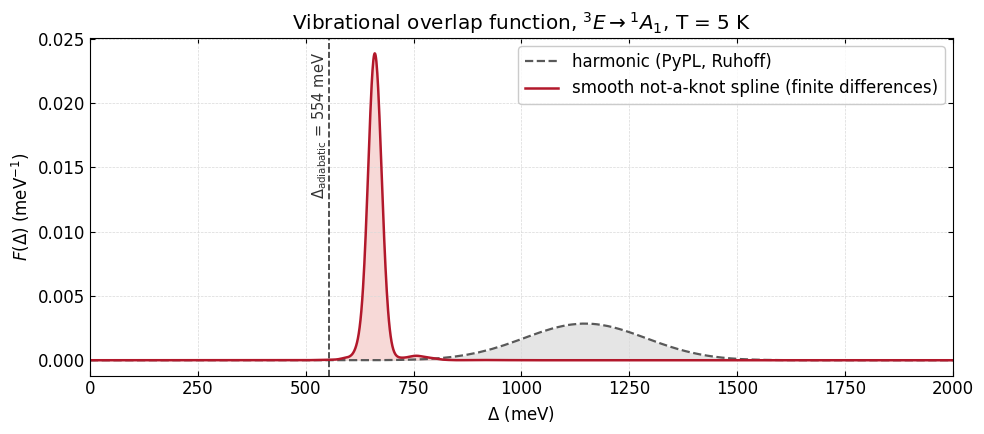

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(Delta_axis, F_harm, color="0.6", alpha=0.25, lw=0)
ax.plot(Delta_axis, F_harm, color="0.35", lw=1.6, ls="--", label="harmonic (PyPL, Ruhoff)")
ax.fill_between(Delta_axis, F_spline, color=red, alpha=0.2, lw=0)
ax.plot(Delta_axis, F_spline, color="#B2182B", lw=1.8, label="smooth not-a-knot spline (finite differences)")
ax.axvline(delta_highlight_meV, color="#333333", ls="--", lw=1.2)
ax.text(delta_highlight_meV, ax.get_ylim()[1] * 0.97, r"$\Delta_\mathrm{adiabatic}$ = %.0f meV  " % delta_highlight_meV,
        rotation=90, va="top", ha="right", fontsize=10.5, color="#333333")
ax.set_xlim(delta_min_meV, delta_max_meV)
ax.set_xlabel(r"$\Delta$ (meV)")
ax.set_ylabel(r"$F(\Delta)$ (meV$^{-1}$)")
ax.set_title(r"Vibrational overlap function, $^3E \rightarrow {}^1A_1$, T = %g K" % temp)
ax.legend(edgecolor="0.75")
ax.grid(color="0.85", ls="--", lw=0.5)
ax.tick_params(direction="in")
ax.xaxis.set_ticks_position("both")
ax.yaxis.set_ticks_position("both")
plt.tight_layout()
plt.show()

**What sets the spline VOF?** It is a single narrow peak, almost as narrow as the broadening itself, which means the
$^3E$ ground state overlaps only one or two $^1A_1$ levels. The cell below lists the largest overlaps and where those
$^1A_1$ states live.

In [12]:
w0 = ccd_spline.fc_ints[0] ** 2
Q_grid, psi_1a1 = ccd_spline.fd_q, ccd_spline.fd_wavefunctions_f
print("largest |<chi_0(3E)|chi_j(1A1)>|^2 (spline):")
for j in np.argsort(w0)[::-1][:5]:
    near = np.sum(psi_1a1[j][Q_grid < 0.8] ** 2) / np.sum(psi_1a1[j] ** 2)
    print("  j = %2d   E_j - E_0 = %6.1f meV   |F_0j|^2 = %.4f   probability at Q < 0.8 = %.2f" % (j, levels_1a1[j], w0[j], near))
print("two largest together: %.3f" % np.sort(w0)[-2:].sum())

qq = np.linspace(-0.6, 0.8, 1401)
v = spline_1a1(qq)
left, right = qq < 0.1, qq > -0.2
q_pocket, q_barrier = qq[left][np.argmin(v[left])], qq[right][np.argmax(v[right])]
v_pocket, v_barrier = spline_1a1(np.array([q_pocket]))[0], spline_1a1(np.array([q_barrier]))[0]
print("\n1A1 spline near the 3E geometry: local minimum %.4f eV at Q = %+.2f, barrier %.4f eV at Q = %+.2f (pocket %.0f meV deep)"
      % (v_pocket, q_pocket, v_barrier, q_barrier, 1e3 * (v_barrier - v_pocket)))
print("1A1 images in that region:", ", ".join("q = %+.2f: %.4f eV" % (q, e) for q, e in zip(q_1a1, e_1a1) if -0.25 < q < 0.35))

largest |<chi_0(3E)|chi_j(1A1)>|^2 (spline):
  j = 18   E_j - E_0 =  657.0 meV   |F_0j|^2 = 0.6381   probability at Q < 0.8 = 0.70
  j = 19   E_j - E_0 =  669.9 meV   |F_0j|^2 = 0.2854   probability at Q < 0.8 = 0.50
  j = 17   E_j - E_0 =  629.3 meV   |F_0j|^2 = 0.0378   probability at Q < 0.8 = 0.27
  j = 22   E_j - E_0 =  755.8 meV   |F_0j|^2 = 0.0117   probability at Q < 0.8 = 0.41
  j = 20   E_j - E_0 =  698.9 meV   |F_0j|^2 = 0.0064   probability at Q < 0.8 = 0.39
two largest together: 0.924

1A1 spline near the 3E geometry: local minimum 3.2316 eV at Q = -0.13, barrier 3.2683 eV at Q = +0.25 (pocket 37 meV deep)
1A1 images in that region: q = -0.20: 3.6126 eV, q = -0.10: 3.2666 eV, q = -0.05: 3.2319 eV, q = +0.00: 3.2404 eV, q = +0.05: 3.2630 eV, q = +0.10: 3.2653 eV, q = +0.15: 3.2331 eV, q = +0.20: 3.1720 eV, q = +0.25: 3.0955 eV, q = +0.30: 3.0280 eV


About 90% of the overlap goes into two $^1A_1$ states (here $j = 18, 19$) with much of their weight on the $^3E$ side,
in the shallow pocket that the spin-flip root 4 forms near $q \approx 0$. Its images there (the shoulder about 0.1 eV
above $^3E$, see the right panel of the CCD figure) make a well about 37 meV deep, and every spline through those images
keeps it. So **the spline VOF, and the rate below, are only as reliable as the $^1A_1$ root near the $^3E$ geometry.**
If that shoulder is an avoided crossing or spin contamination in the spin-flip TDDFT rather than the true $^1A_1$
surface, the pocket is an artefact and the rate will change. It is worth checking, e.g. with denser images or more
spin-flip roots, before quoting the spline rate.

## 4. Huang-Rhys factors beyond the harmonic approximation

The Huang-Rhys factor $S = \omega\,\Delta Q^2 / 2\hbar$ of section 2 is the mean number of phonons emitted when the
lattice relaxes after the transition. It is defined for two identical parabolas, and then several quantities are all
equal to it: the relaxation energy in units of $\hbar\omega$, the centroid of the phonon sideband, the mean final
quantum number of the Poisson weights $|F_{0n}|^2 = e^{-S} S^n / n!$, and $-\ln$ of the zero-phonon weight. On an
anharmonic PES these quantities differ, so each defines its own generalized Huang-Rhys factor. With $\chi_0$ the
vibrational ground state of the *other* well (the initial state of the transition) and $\chi_n$, $\varepsilon_n$ the
eigenstates of the well considered:

| Definition | Expression | Keeps the meaning of $S$ as |
| --- | --- | --- |
| classical relaxation | $S_\mathrm{cl} = \dfrac{V(Q^{\min}_\mathrm{other}) - V(Q^{\min})}{\hbar\omega}$ | vertical relaxation energy on the PES, in phonons |
| energy moment | $S_E = \dfrac{\sum_n |F_{0n}|^2(\varepsilon_n - \varepsilon_0)}{\hbar\omega} = \dfrac{\langle\chi_0|\hat H|\chi_0\rangle - \varepsilon_0}{\hbar\omega}$ | centroid of the sideband (Franck-Condon shift) |
| mean quantum number | $S_n = \sum_n n\,|F_{0n}|^2$ | mean number of phonons emitted |
| Debye-Waller | $S_\mathrm{DW} = -\ln|F_{00}|^2$ | weight of the zero-phonon line |

Here $\hbar\omega = \varepsilon_1 - \varepsilon_0$ is the fundamental of the well, from the same eigenvalues (for the
spline this differs from the curvature at the minimum printed in section 2). The second form of $S_E$ is an exact sum
rule: the first moment of the weights is the expectation value of the well's Hamiltonian in $\chi_0$, so it needs no sum
over levels and checks the closure of the basis.

Two harmonic details are worth knowing before reading the numbers. With unequal frequencies $\omega_0$ (initial) and
$\omega$ (final), $S_E$ exceeds $S$ by the zero-point term $(\omega_0 - \omega)^2 / 4\omega_0\omega$, and
$|F_{00}|^2 = \frac{2\sqrt{\omega_0\omega}}{\omega_0 + \omega}\,e^{-2 S_0 S / (S_0 + S)}$ is shared by both wells, so
$S_\mathrm{DW}$ is not a property of one well even for parabolas.

The cell below evaluates the four definitions with the same finite-difference solver on both pairs of wells, with
more levels than the VOF of section 3 (the harmonic $^3E$ well, $S \approx 70$, needs about 140 to close), so that
$\sum_n |F_{0n}|^2 = 1$ in both directions. "$^1A_1$ well" is the relaxation after $^3E \rightarrow {}^1A_1$ (the ISC,
$\chi_0$ = $^3E$ ground state); "$^3E$ well" is the relaxation after $^1A_1 \rightarrow {}^3E$.

In [13]:
from pypl.config_coord_1d_vof_solver import KINETIC  # hbar^2 / 2 in eV amu A^2

hr_levels_3e, hr_levels_1a1 = 220, 160


def generalized_huang_rhys(solver, pot, pot_other, well):
    """Generalized Huang-Rhys factors of one well of an FD solver: well = "i" (initial PES) or "f" (final PES)."""
    eps = getattr(solver, "fd_energies_" + well)  # eV
    if well == "f":
        weights, chi_0 = solver.fc_ints[0, :] ** 2, solver.fd_wavefunctions_i[0]
    else:
        weights, chi_0 = solver.fc_ints[:, 0] ** 2, solver.fd_wavefunctions_f[0]
    h = solver.fd_info["h"]
    hw = eps[1] - eps[0]
    # <chi_0|H|chi_0> on the grid: kinetic energy K int |chi_0'|^2 dQ plus the potential
    expect_h = KINETIC * np.sum(np.gradient(chi_0, h) ** 2) * h + np.sum(chi_0**2 * pot(solver.fd_q)) * h
    e_relax = pot(np.array([pot_other.minimum()[0]]))[0] - pot.minimum()[1]
    return {
        "hw": hw * 1e3,
        "closure": np.sum(weights),
        "S_cl": e_relax / hw,
        "S_E": np.sum(weights * (eps - eps[0])) / hw,
        "S_E_rule": (expect_h - eps[0]) / hw,
        "S_n": np.sum(np.arange(len(eps)) * weights),
        "S_DW": -np.log(weights[0]),
        "weights": weights,
    }


hr, hr_solvers = {}, {}
for pes, (p_3e, p_1a1) in (("harmonic", (harm_3e, harm_1a1)), ("spline", (spline_3e, spline_1a1))):
    solver = config_coord_1d_vof_solver(omega_i=phonon_3e, omega_f=phonon_1a1, delta_q=delta_q)
    solver.compute_franck_condon_integrals_fd(hr_levels_3e, hr_levels_1a1, p_3e, p_1a1, q_i=0.0, q_f=delta_q, npts=fd_npts)
    hr[pes, "1A1"] = generalized_huang_rhys(solver, p_1a1, p_3e, "f")
    hr[pes, "3E"] = generalized_huang_rhys(solver, p_3e, p_1a1, "i")
    hr_solvers[pes] = solver

print("=" * 98)
print("              GENERALIZED HUANG-RHYS FACTORS (FD, %d x %d levels, %d points)" % (hr_levels_3e, hr_levels_1a1, fd_npts))
print("=" * 98)
print("%-9s %-5s %10s %9s %8s %8s %13s %8s %8s %12s" % ("PES", "well", "hw (meV)", "closure", "S_cl", "S_E",
                                                         "S_E sum rule", "S_n", "S_DW", "S_E hw (meV)"))
for (pes, well), r in hr.items():
    print("%-9s %-5s %10.2f %9.6f %8.2f %8.2f %13.2f %8.2f %8.2f %12.1f" % (pes, well, r["hw"], r["closure"], r["S_cl"],
          r["S_E"], r["S_E_rule"], r["S_n"], r["S_DW"], r["S_E"] * r["hw"]))
print("-" * 98)
print("harmonic S = omega dQ^2 / 2 hbar: 3E %.2f, 1A1 %.2f" % (huang_rhys(phonon_3e), huang_rhys(phonon_1a1)))
for well, w0, w in (("1A1", phonon_3e, phonon_1a1), ("3E", phonon_1a1, phonon_3e)):
    print("harmonic zero-point term (w0 - w)^2 / 4 w0 w, %-3s well: %.3f" % (well, (w0 - w) ** 2 / (4 * w0 * w)))
s_i, s_f = huang_rhys(phonon_3e), huang_rhys(phonon_1a1)
dw = 2 * s_i * s_f / (s_i + s_f) - np.log(2 * np.sqrt(phonon_3e * phonon_1a1) / (phonon_3e + phonon_1a1))
print("harmonic Debye-Waller formula: S_DW = %.2f" % dw)
print("VOF centroids of section 3 (meV): harmonic %.1f, spline %.1f" % (centroid(F_harm), centroid(F_spline)))
print("=" * 98)

              GENERALIZED HUANG-RHYS FACTORS (FD, 220 x 160 levels, 40001 points)
PES       well    hw (meV)   closure     S_cl      S_E  S_E sum rule      S_n     S_DW S_E hw (meV)
harmonic  1A1        31.55  1.000000    36.22    36.33         36.33    36.33    47.75       1146.2
harmonic  3E         60.83  1.000000    69.83    69.94         69.94    69.94    47.75       4254.8
spline    1A1        42.54  1.000000    15.45    15.57         15.57    18.36    47.29        662.2
spline    3E         72.66  1.000000    22.78    22.24         22.24    30.78    47.29       1616.3
--------------------------------------------------------------------------------------------------
harmonic S = omega dQ^2 / 2 hbar: 3E 69.83, 1A1 36.22
harmonic zero-point term (w0 - w)^2 / 4 w0 w, 1A1 well: 0.112
harmonic zero-point term (w0 - w)^2 / 4 w0 w, 3E  well: 0.112
harmonic Debye-Waller formula: S_DW = 47.75
VOF centroids of section 3 (meV): harmonic 1146.2, spline 662.2


**Reading the table.**

- **Harmonic wells.** $S_\mathrm{cl}$ is the tutorial $S$ (69.83 / 36.22), and $S_E = S_n$ exceed it by exactly the
  zero-point term (0.11), as derived above. $S_\mathrm{DW}$ matches the closed-form harmonic expression.
- **Spline wells.** Every definition drops: the $^1A_1$ well goes from 36 to $S_E \approx 16$ and the $^3E$ well from
  70 to $S_E \approx 22$. The real surfaces are stiffer near their minima (larger $\hbar\omega$) and give a much smaller
  relaxation energy than the parabolas extrapolated over $\Delta Q \approx 3.1$ amu$^{1/2}$ Å.
- **The energy moment is the sideband centroid.** $S_E\,\hbar\omega$ of the $^1A_1$ well reproduces the centroid of the
  VOF of section 3 for both PES models (it is the same first moment, without broadening), and the sum rule agrees with
  the level sum, so the basis is closed.
- **The definitions disagree on the spline.** $S_n > S_E$ because the ladder is uneven: on the $^1A_1$ side the pocket
  near $q \approx 0$ adds levels, so the same energy takes more quanta.

The weights below show why no single number replaces the VOF. For the parabolas they form one smooth band centred at
$S_n$, somewhat narrower than the Poisson distribution because the two wells have different frequencies. For the spline,
most of the weight sits in two levels, which no Poisson distribution reproduces.

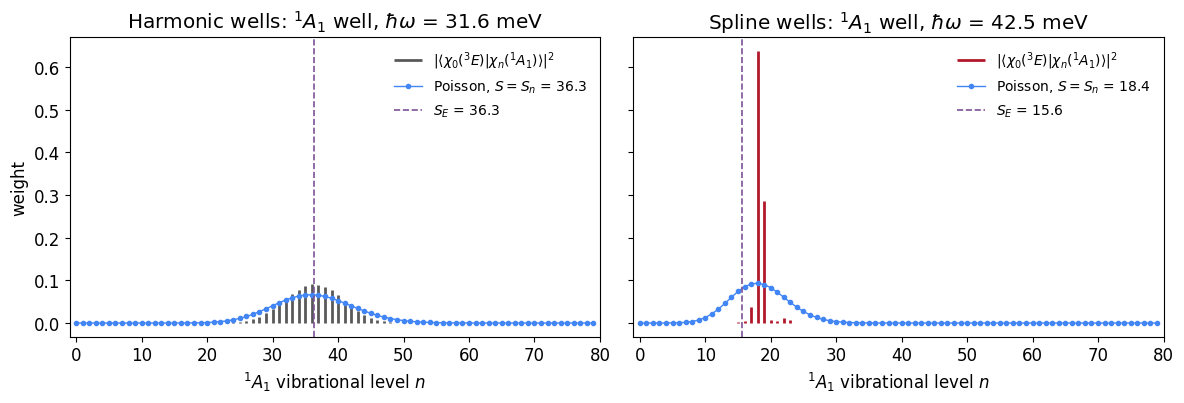

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
n_max = 80
for ax, pes, color in zip(axes, ("harmonic", "spline"), ("0.35", "#B2182B")):
    r = hr[pes, "1A1"]
    n = np.arange(n_max)
    poisson = np.exp(-r["S_n"] + n * np.log(r["S_n"]) - np.cumsum(np.log(np.maximum(n, 1))))
    ax.vlines(n, 0, r["weights"][:n_max], color=color, lw=2.0, label=r"$|\langle\chi_0(^3E)|\chi_n(^1A_1)\rangle|^2$")
    ax.plot(n, poisson, "o-", color=blue, ms=3, lw=1, label=r"Poisson, $S = S_n$ = %.1f" % r["S_n"])
    ax.axvline(r["S_E"], color="#7A5195", ls="--", lw=1.2, label=r"$S_E$ = %.1f" % r["S_E"])
    ax.set_title("%s wells: $^1A_1$ well, $\\hbar\\omega$ = %.1f meV" % (pes.capitalize(), r["hw"]))
    ax.set_xlabel(r"$^1A_1$ vibrational level $n$")
    ax.set_xlim(-1, n_max)
    ax.legend(frameon=False, fontsize=10)
axes[0].set_ylabel("weight")
plt.tight_layout()
plt.show()

**Which one to use.** $S_E$ is the natural generalization: it reduces to $S$ for parabolas (up to the zero-point term),
it is the measurable Franck-Condon shift in phonon units, and the sum rule makes it cheap and closure-free. Quote it
with the $\hbar\omega$ it was divided by. $S_\mathrm{DW}$ is the one to use for the zero-phonon-line weight, and the
spread between $S_\mathrm{cl}$, $S_E$ and $S_n$ is itself a measure of anharmonicity. None of them determines the ISC
rate: $\Gamma$ depends on the weights near $\Delta_\mathrm{adiabatic}$, here concentrated in two $^1A_1$ levels, which a
Poisson distribution with any single $S$ does not reproduce.

## 5. Intersystem crossing rate and lifetime

With Fermi's golden rule (Eq. 1 of Jin *et al.*, Phys. Rev. Lett. **135**, 036401 (2025)),

$$\Gamma_{A_1}(\Delta) = \frac{4\pi}{\hbar}\,|\lambda_\perp|^2\,F(\Delta), \qquad \tau_{A_1}(\Delta) = 1/\Gamma_{A_1}(\Delta),$$

with the transverse spin-orbit coupling $\lambda_\perp$ from quantum defect embedding theory (QDET).

In [15]:
# SOC matrix element (lambda_perp) from QDET, in GHz
lambda_perp_qdet_GHz = 204.992500
print("lambda_perp (QDET) = %.4f GHz = %.4f ueV" % (lambda_perp_qdet_GHz, const.h * lambda_perp_qdet_GHz * 1e9 / const.eV * 1e6))


def select_unit(value, units):
    for name, divisor in units:
        if value / divisor >= 1:
            return name, divisor
    return units[-1]


RATE_UNITS = [("THz", 1e12), ("GHz", 1e9), ("MHz", 1e6), ("kHz", 1e3), ("Hz", 1.0)]
TIME_UNITS = [("s", 1.0), ("ms", 1e-3), ("us", 1e-6), ("ns", 1e-9), ("ps", 1e-12)]

# Gamma(Delta) = 4 pi / hbar |lambda_perp|^2 F(Delta), in Hz (F in 1/meV)
Gamma_harm_Hz = compute_isc_rate(lambda_perp_qdet_GHz, F_harm, soc_unit="GHz")
Gamma_spline_Hz = compute_isc_rate(lambda_perp_qdet_GHz, F_spline, soc_unit="GHz")

lambda_perp (QDET) = 204.9925 GHz = 847.7809 ueV


In [16]:
results = {}
for name, F, G in (("harmonic (PyPL, Ruhoff)", F_harm, Gamma_harm_Hz), ("smooth not-a-knot spline", F_spline, Gamma_spline_Hz)):
    g_ad = np.interp(delta_highlight_meV, Delta_axis, G)
    results[name] = {
        "fc_shift": Delta_axis[np.argmax(F)],
        "gamma_ad": g_ad,
        "tau_ad": 1.0 / g_ad if g_ad > 0 else np.nan,
        "gamma_max": G.max(),
        "delta_max": Delta_axis[np.argmax(G)],
    }

ref = results["smooth not-a-knot spline"]
rate_unit, rate_div = select_unit(max(r["gamma_ad"] for r in results.values()), RATE_UNITS)
tau_unit, tau_div = select_unit(min(r["tau_ad"] for r in results.values()), TIME_UNITS)

print("=" * 78)
print("          ISC RATE / LIFETIME, 3E -> 1A1, lambda_perp (QDET) = %.2f GHz" % lambda_perp_qdet_GHz)
print("=" * 78)
print("At Delta_adiabatic = %.2f meV:" % delta_highlight_meV)
for name, r in results.items():
    print("  %-26s Gamma = %10.4g %s   tau = %10.4g %s" % (name, r["gamma_ad"] / rate_div, rate_unit, r["tau_ad"] / tau_div, tau_unit))
print("  ratio spline / harmonic: %.3e" % (ref["gamma_ad"] / results["harmonic (PyPL, Ruhoff)"]["gamma_ad"]))
print("\nFranck-Condon shift (peak of F) and maximum rate over Delta = %g..%g meV:" % (delta_min_meV, delta_max_meV))
for name, r in results.items():
    print("  %-26s FC shift = %7.1f meV   Gamma_max = %10.4g %s" % (name, r["fc_shift"], r["gamma_max"] / rate_div, rate_unit))
print("=" * 78)

          ISC RATE / LIFETIME, 3E -> 1A1, lambda_perp (QDET) = 204.99 GHz
At Delta_adiabatic = 554.41 meV:
  harmonic (PyPL, Ruhoff)    Gamma =      3.711 MHz   tau =      269.5 ns
  smooth not-a-knot spline   Gamma =      554.9 MHz   tau =      1.802 ns
  ratio spline / harmonic: 1.495e+02

Franck-Condon shift (peak of F) and maximum rate over Delta = 0..2000 meV:
  harmonic (PyPL, Ruhoff)    FC shift =  1145.0 meV   Gamma_max =  3.908e+04 MHz
  smooth not-a-knot spline   FC shift =   660.0 meV   Gamma_max =  3.274e+05 MHz


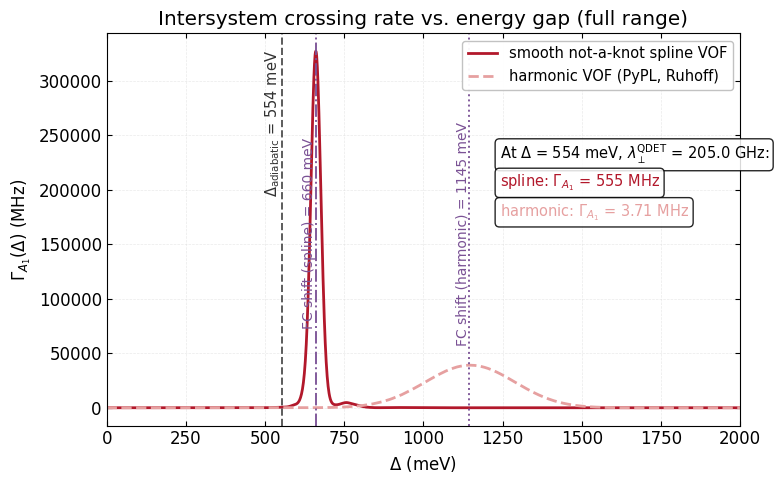

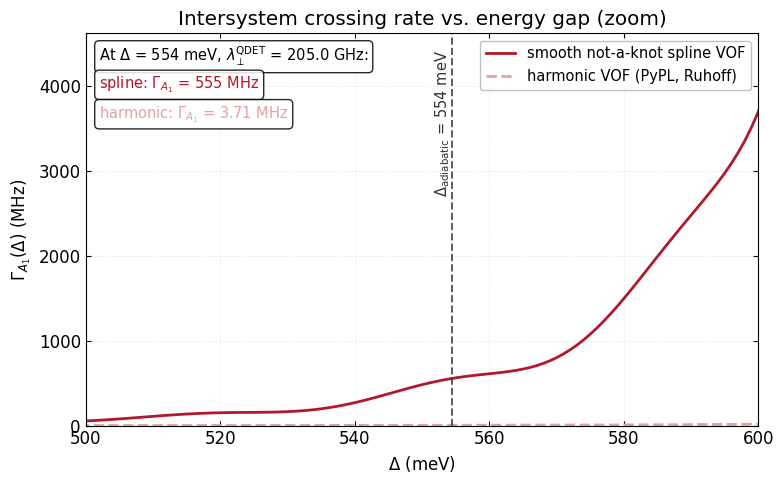

In [17]:
HARM_COLOR, SPLINE_COLOR = "#E6A0A0", "#B2182B"  # light and dark red
FC_SHIFT_COLOR, ADIABATIC_COLOR = "#7A5195", "#333333"
curve_label = {
    "harmonic (PyPL, Ruhoff)": r"harmonic VOF (PyPL, Ruhoff)",
    "smooth not-a-knot spline": r"smooth not-a-knot spline VOF",
}


def decorate(ax, ylabel, xlim):
    ax.axvline(delta_highlight_meV, color=ADIABATIC_COLOR, ls="--", lw=1.4, alpha=0.8)
    ax.text(delta_highlight_meV, 0.97, r"$\Delta_{\mathrm{adiabatic}}$ = %.0f meV  " % delta_highlight_meV,
            transform=ax.get_xaxis_transform(), rotation=90, va="top", ha="right", fontsize=10.5, color=ADIABATIC_COLOR)
    for name, ls in (("harmonic (PyPL, Ruhoff)", ":"), ("smooth not-a-knot spline", "-.")):
        x = results[name]["fc_shift"]
        if xlim[0] <= x <= xlim[1]:
            ax.axvline(x, color=FC_SHIFT_COLOR, ls=ls, lw=1.4, alpha=0.95)
            ax.text(x, 0.5, "FC shift (%s) = %.0f meV  " % ("harmonic" if "harm" in name else "spline", x),
                    transform=ax.get_xaxis_transform(), rotation=90, va="center", ha="right", fontsize=10, color=FC_SHIFT_COLOR)
    ax.set_xlim(*xlim)
    ax.set_xlabel(r"$\Delta$ (meV)")
    ax.set_ylabel(ylabel)
    ax.grid(color="0.85", ls="--", lw=0.5, alpha=0.55)
    ax.tick_params(direction="in")
    ax.xaxis.set_ticks_position("both")
    ax.yaxis.set_ticks_position("both")
    ax.legend(fontsize=10.5, edgecolor="0.75", framealpha=0.95, loc="upper right")


def value_box(ax, quantity, unit, div, x=0.02, y=0.97):
    lines = [r"At $\Delta$ = %.0f meV, $\lambda_\perp^{\mathrm{QDET}}$ = %.1f GHz:" % (delta_highlight_meV, lambda_perp_qdet_GHz)]
    for name, color in (("smooth not-a-knot spline", SPLINE_COLOR), ("harmonic (PyPL, Ruhoff)", HARM_COLOR)):
        lines.append((r"%s: %s = %.3g %s" % ("spline" if "spline" in name else "harmonic", quantity, results[name][quantity_key[quantity]] / div, unit), color))
    ax.text(x, y, lines[0], transform=ax.transAxes, va="top", ha="left", fontsize=10.5,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))
    for k, (text, color) in enumerate(lines[1:], 1):
        ax.text(x, y - 0.075 * k, text, transform=ax.transAxes, va="top", ha="left", fontsize=10.5, color=color,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="black", alpha=0.85))


quantity_key = {r"$\Gamma_{A_1}$": "gamma_ad", r"$\tau_{A_1}$": "tau_ad"}

# ISC rate, full range and zoom
for xlim, title, box in (((delta_min_meV, delta_max_meV), "Intersystem crossing rate vs. energy gap (full range)", (0.62, 0.72)),
                         ((500, 600), "Intersystem crossing rate vs. energy gap (zoom)", (0.02, 0.97))):
    fig, ax = plt.subplots(figsize=(8.0, 5.0))
    ax.plot(Delta_axis, Gamma_spline_Hz / rate_div, color=SPLINE_COLOR, lw=2.0, label=curve_label["smooth not-a-knot spline"])
    ax.plot(Delta_axis, Gamma_harm_Hz / rate_div, color=HARM_COLOR, lw=2.0, ls="--", label=curve_label["harmonic (PyPL, Ruhoff)"])
    if xlim[1] - xlim[0] < 500:
        inside = (Delta_axis >= xlim[0]) & (Delta_axis <= xlim[1])
        top = max(Gamma_spline_Hz[inside].max(), Gamma_harm_Hz[inside].max()) / rate_div
        ax.set_ylim(0, 1.25 * top)
    decorate(ax, r"$\Gamma_{A_1}(\Delta)$ (%s)" % rate_unit, xlim)
    value_box(ax, r"$\Gamma_{A_1}$", rate_unit, rate_div, *box)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

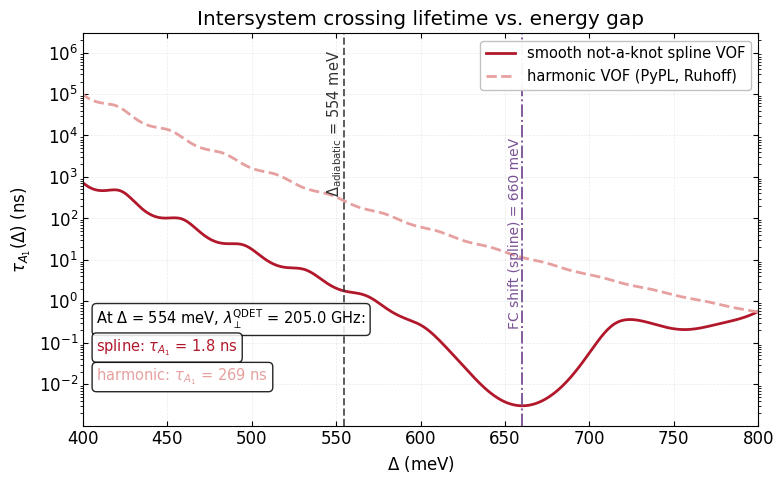

In [18]:
# ISC lifetime near the adiabatic gap
# tau = 1 / Gamma (infinite where Gamma = 0; left out of the log plot)
tau_harm_s = compute_isc_lifetime(Gamma_harm_Hz)
tau_spline_s = compute_isc_lifetime(Gamma_spline_Hz)
tau_harm_s[~np.isfinite(tau_harm_s)] = np.nan
tau_spline_s[~np.isfinite(tau_spline_s)] = np.nan

fig, ax = plt.subplots(figsize=(8.0, 5.0))
ax.semilogy(Delta_axis, tau_spline_s / tau_div, color=SPLINE_COLOR, lw=2.0, label=curve_label["smooth not-a-knot spline"])
ax.semilogy(Delta_axis, tau_harm_s / tau_div, color=HARM_COLOR, lw=2.0, ls="--", label=curve_label["harmonic (PyPL, Ruhoff)"])
inside = (Delta_axis >= 400) & (Delta_axis <= 800)
visible = np.concatenate([tau_spline_s[inside], tau_harm_s[inside]]) / tau_div
ax.set_ylim(np.nanmin(visible) / 3, np.nanmax(visible) * 30)
decorate(ax, r"$\tau_{A_1}(\Delta)$ (%s)" % tau_unit, (400, 800))
value_box(ax, r"$\tau_{A_1}$", tau_unit, tau_div, 0.02, 0.30)
ax.set_title("Intersystem crossing lifetime vs. energy gap")
plt.tight_layout()
plt.show()

**Summary.** Both VOFs use the same WEST data, $\Delta Q$ and broadening; they differ only in the potentials.

- **Harmonic (PyPL, Ruhoff).** The parabolas describe each PES only near its own minimum. They put the overlap at
  energy gaps around 1.15 eV (rms width 0.14 eV), about twice the adiabatic gap, so at $\Delta_\mathrm{adiabatic}$ the
  harmonic VOF samples only its low-energy tail: $\Gamma_{A_1} \approx 3.7$ MHz ($\tau \approx 270$ ns) with
  $\lambda_\perp^\mathrm{QDET}$.
- **Smooth not-a-knot spline.** The spline follows every image. Its $^1A_1$ surface rises far less steeply towards
  the $^3E$ geometry than the parabola, so the overlap moves to about 0.66 eV, close to the adiabatic gap, and
  $\Gamma_{A_1}(\Delta_\mathrm{adiabatic}) \approx 555$ MHz ($\tau \approx 1.8$ ns), about 150 times the harmonic rate.
  The VOF is a narrow peak from two $^1A_1$ states in the pocket of the spin-flip root near $q \approx 0$, and
  $\Delta_\mathrm{adiabatic}$ lies on its steep low-energy flank, so the rate there also depends strongly on the exact
  gap (see the zoomed plot).
- **Huang-Rhys factors.** On the spline wells the generalized factors drop to $S_E \approx 16$ ($^1A_1$) and $\approx 22$ ($^3E$) from the harmonic 36 and 70 (section 4); $S_E\,\hbar\omega$ is the VOF centroid, but no single $S$ reproduces the spline weights.

Limits of both: the 1D CCD keeps a single effective mode along the $^3E \rightarrow {}^1A_1$ path, and $F$ is evaluated
at $\Delta$ measured from each VOF's own 0-0 line; the 0-0 energies with zero-point energy
(printed in section 3) differ from $\Delta_\mathrm{adiabatic}$ by about 25 meV (harmonic) and 17 meV (spline). For the
spline, the decisive uncertainty is the $^1A_1$ surface near the $^3E$ geometry, not the fitting method.

The full comparison of methods and fits (Hermite, finite differences, splines, polynomials, Morse, cubic perturbation
theory) for this dataset is in `validation/outputs/suite/nv_mgo/index.md` (`python validation/run_all.py --config
validation/run_all_nv_mgo.toml`).